In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import kagglehub
from tensorflow import keras
from sklearn.model_selection import StratifiedGroupKFold
from google.colab import files

BASE = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
df = pd.read_csv(f"{BASE}/HAM10000_metadata.csv")

paths = {}
for part in ["HAM10000_images_part_1", "HAM10000_images_part_2"]:
    d = f"{BASE}/{part}"
    for f in os.listdir(d):
        paths[f.replace(".jpg", "")] = f"{d}/{f}"
df["path"] = df["image_id"].map(paths)

def split(data, n_splits, seed=42):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    rest, part = next(sgkf.split(data, data["dx"], groups=data["lesion_id"]))
    return data.iloc[rest], data.iloc[part]

train_val, test = split(df, 10)
CLASSES = sorted(df["dx"].unique())
IMG_SIZE = 128

files.upload()
model = keras.models.load_model("mobilenetv2_ft.keras")
print([l.name for l in model.layers])

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.


Saving mobilenetv2_ft.keras to mobilenetv2_ft.keras
['input_layer_1', 'augmentation', 'rescaling', 'mobilenetv2_1.00_128', 'global_average_pooling2d', 'dropout', 'dense']


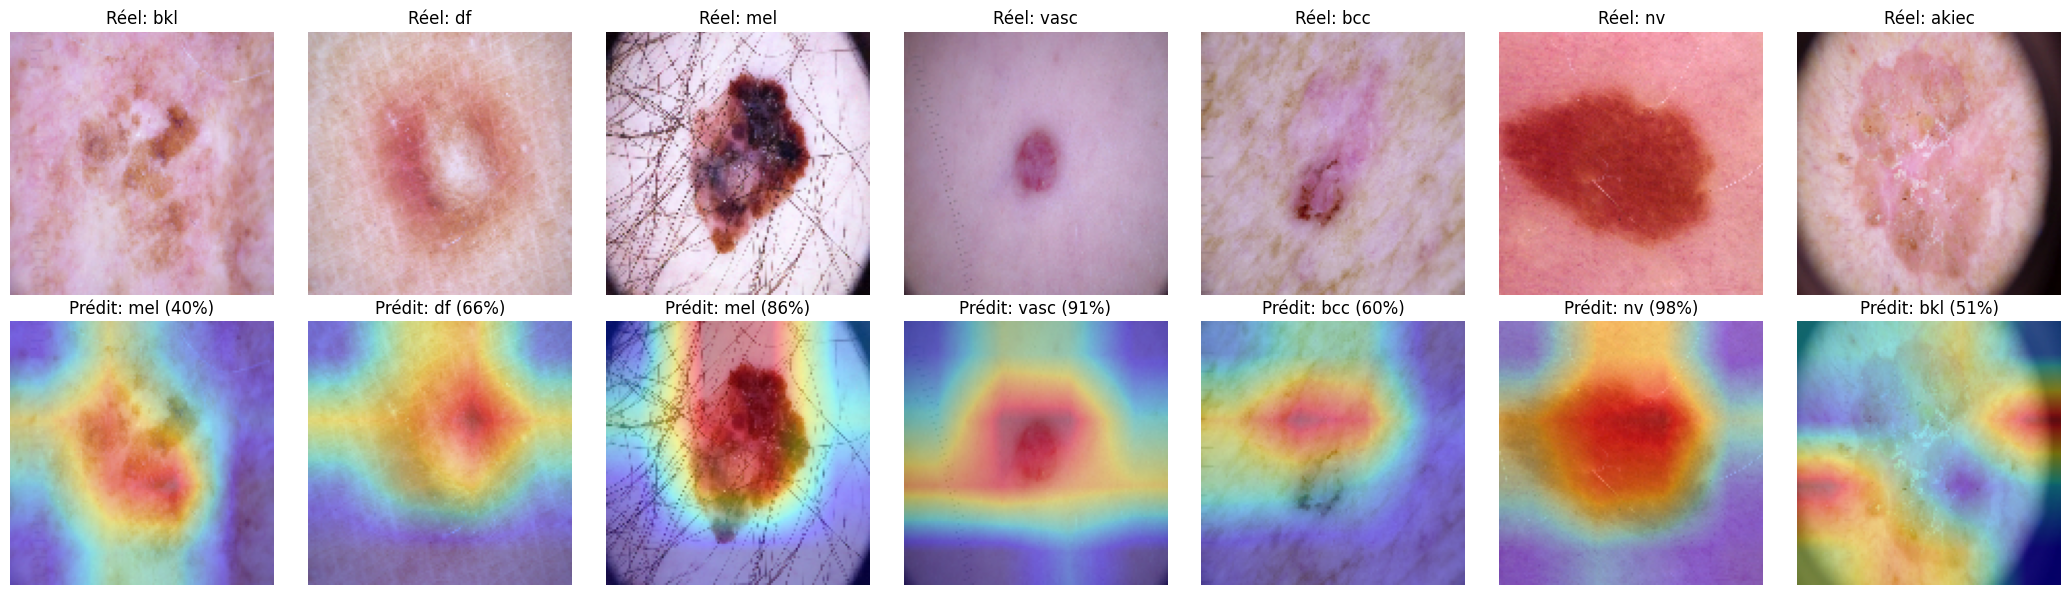

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

base = next(l for l in model.layers if isinstance(l, keras.Model) and l.name.startswith("mobilenetv2"))
conv_model = keras.Model(base.input, base.get_layer("out_relu").output)
head_layers = model.layers[model.layers.index(base) + 1:]

def load_img(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    return tf.image.resize(img, (IMG_SIZE, IMG_SIZE)).numpy()

def gradcam(img, class_idx=None):
    x = tf.convert_to_tensor(img[None], tf.float32) / 127.5 - 1.0
    with tf.GradientTape() as tape:
        conv = conv_model(x)
        tape.watch(conv)
        h = conv
        for l in head_layers:
            h = l(h)
        if class_idx is None:
            class_idx = int(tf.argmax(h[0]))
        score = h[:, class_idx]
    grads = tape.gradient(score, conv)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.reduce_sum(conv * weights[:, None, None, :], axis=-1)[0]
    cam = tf.nn.relu(cam)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), class_idx, h[0].numpy()

def overlay(img, cam, alpha=0.4):
    cam_r = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE)).numpy()[..., 0]
    heat = cm.jet(cam_r)[..., :3] * 255
    return np.uint8((1 - alpha) * img + alpha * heat)

samples = test.groupby("dx").head(1)
fig, axes = plt.subplots(2, len(samples), figsize=(3 * len(samples), 6))
for i, (_, row) in enumerate(samples.iterrows()):
    img = load_img(row["path"])
    cam, pred, probs = gradcam(img)
    axes[0, i].imshow(img.astype("uint8"))
    axes[0, i].set_title(f"Réel: {row['dx']}")
    axes[1, i].imshow(overlay(img, cam))
    axes[1, i].set_title(f"Prédit: {CLASSES[pred]} ({probs[pred]:.0%})")
    for a in axes[:, i]:
        a.axis("off")
plt.tight_layout()
plt.savefig("gradcam_examples.png", dpi=150, bbox_inches="tight")
plt.show()
files.download("gradcam_examples.png")